# 1. LSTM (Long Short-Term Memory)

- LSTM(Long Short-Term Memory)은 RNN의 장기 의존성 문제를 해결하기 위해 고안된 모델입니다. 
- LSTM은 셀 상태(cell state)와 3개의 게이트(입력 게이트, 출력 게이트, 망각 게이트)를 사용하여 중요한 정보를 오랫동안 저장하고 불필요한 정보를 제거하는 구조를 갖추고 있습니다. 
    - 망각 게이트(Forget Gate)는 이전 셀 상태에서 필요 없는 정보를 삭제하고, 
    - 입력 게이트는 새로운 정보를 저장하며, 
    - 출력 게이트는 최종 출력을 결정합니다. 
- 이러한 구조 덕분에 LSTM은 장기 시퀀스를 다루는 자연어 처리, 음성 인식, 시계열 예측 등의 다양한 분야에서 효과적으로 사용됩니다. 
- 하지만 구조가 복잡하여 계산량이 많고, 학습 시간이 오래 걸린다는 단점이 있습니다.

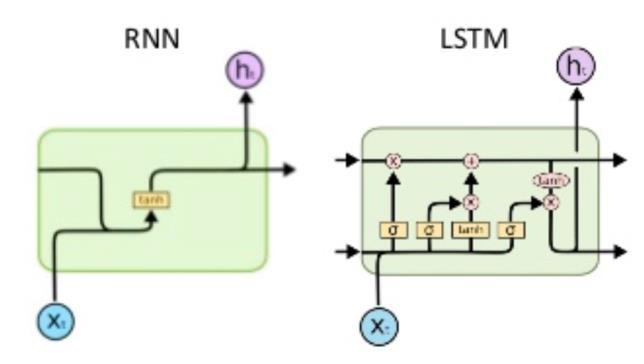
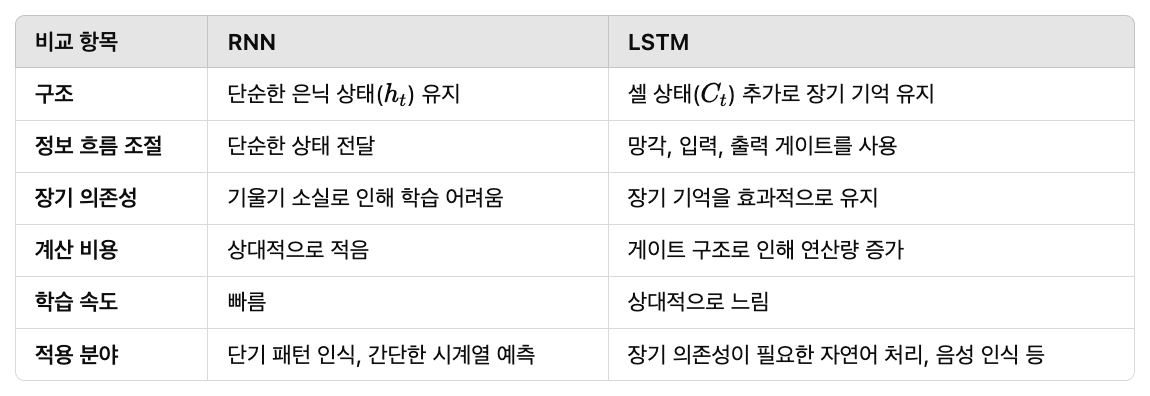

### RNN이 오래된 정보를 잊어버리는 이유
- RNN은 학습할 때 역전파(Backpropagation)를 사용
- 순차 데이터에서는 여러 시점을 거슬러 올라가면서 미분값을 전달해야 함
```
t=1 < t=2 < t=3 < t=4 < ...
0.5 * 0.5 * 0.5 * 0.5 ...
이 과정에서 작은 값이 계속 곱해짐 > 계속 곱하면 값이 매우 작아짐
```

>- 결국 앞쪽 시점까지 도착했을 때 Gradient가 거의 0에 가까워질 수 있음. 0일 때 기울기 소실 문제라고 부름. 
>- 그래서 일반적인 RNN은 멀리 떨어진 정보 사이의 관계를 학습하는 것이 어려움.

### LSTM의 핵심 아이디어

새로운 데이터가 들어옴 > 과거 기억 확인 > 필요 없는 기억 삭제 > 새로운 중요한 정보 추가 > 장기 기억 업데이트 > 현재 필요한 정보 출력 > 다음 데이터 처리


1. Forget Gate: 무엇을 잊을 것인가?
2. Input Gate: 무엇을 새로 기억할 것인가?
3. Output Gate: 무엇을 밖으로 출력할 것인가?
4. Cell State: 실제 장기 기억

### Individual Household Electric Power Consumption 데이터셋
- 한 가정에서 약 4년 동안 1분 간격으로 측정한 전력 사용량 데이터이며 약 207만 개 관측치와 9개 특성을 가지고 있음
- [다운로드](https://archive.ics.uci.edu/dataset/235/individual%2Bhousehold%2Belectric%2Bpower%2Bconsumption?utm_source=chatgpt.com)

In [41]:
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error

warnings.filterwarnings("ignore")

In [3]:
# seed값 정의
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [4]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


In [5]:
DATA_PATH = "./data/household_power_consumption.txt"
df = pd.read_csv(DATA_PATH, sep=";", na_values="?", low_memory=False)  # txt파일이어도 ;로 나뉘어져 있기 때문에 csv로 읽어올 수 있다
print(df.shape)
df.head()

(2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


- `Date` : 날짜
- `Time` : 시간
- `Global_active_power` : 전체 유효전력
- `Global_reactive_power` : 무효전력
- `Voltage` : 전압
- `Global_intensity` : 전류 세기
- `Sub_metering_1~3` : 구역별 전력 사용량

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 142.5 MB


In [7]:
df.isna().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [8]:
# datetime 파생변수 만들기
df['datetime'] = pd.to_datetime(df['Date'] + " " + df['Time'], 
                                format="%d/%m/%Y %H:%M:%S", errors="coerce")  

In [9]:
df = df.sort_values("datetime")
df = df.set_index("datetime")
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [10]:
power = df[['Global_active_power']].copy()

# 전력 값 모두 숫자형으로 변환
power["Global_active_power"] = pd.to_numeric(
    power['Global_active_power'], errors="coerce"  # errors="coerce": 숫자로 바꿀 수 없는 값을 NaN으로 처리
)
power = power.dropna()  # NaN 포함된 행 제거
print(power.shape)

(2049280, 1)


In [11]:
power.head()

,Global_active_power
datetime,
2006-12-16 17:24:00,4.216
2006-12-16 17:25:00,5.360
2006-12-16 17:26:00,5.374
2006-12-16 17:27:00,5.388
2006-12-16 17:28:00,3.666


In [12]:
# 원본 데이터는 2049280행으로 매우 큼
# LSTM 실습에서는 1시간 평균으로 줄여 학습을 가볍게 만듦
# resample("1h").mean(): 같은 1시간 안에 존재하는 1분 단위 값들의 평균을 계산
hourly = power.resample("1h").mean()
hourly = hourly.dropna()
hourly.shape

(34168, 1)

In [13]:
hourly.head()

,Global_active_power
datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467


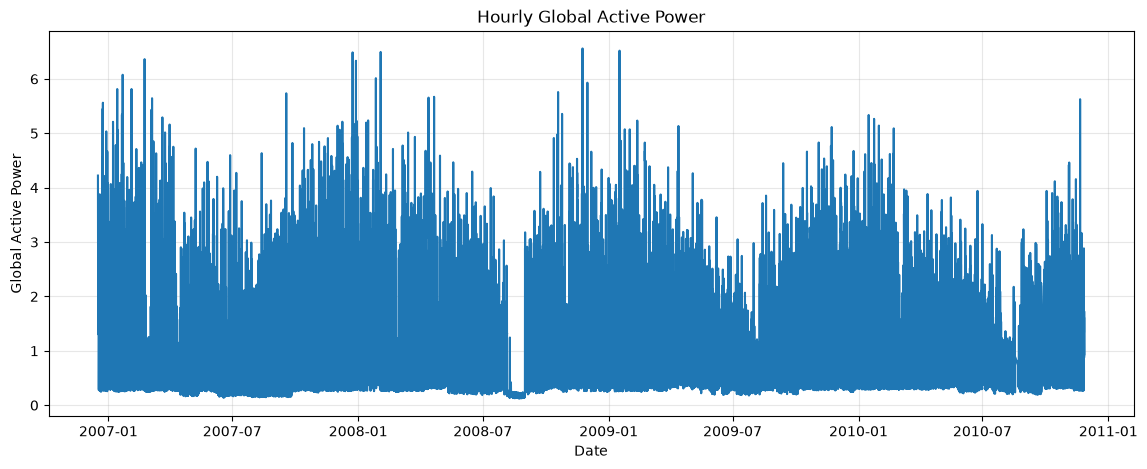

In [14]:
plt.figure(figsize=(14, 5))
plt.plot(hourly.index, hourly["Global_active_power"])
plt.title("Hourly Global Active Power")
plt.xlabel("Date")
plt.ylabel("Global Active Power")
plt.grid(alpha=0.3)
plt.show()

In [15]:
# 한 열로 세우기
values = hourly['Global_active_power'].values.reshape(-1, 1)


In [16]:
n = len(values)
n

34168

In [17]:
train_end = int(n * 0.70)
val_end = int(n * 0.85)
print("전체: ", n)
print("Train: ", train_end)
print("Val: ", val_end - train_end)
print("Test: ", n - val_end)

전체:  34168
Train:  23917
Val:  5125
Test:  5126


In [18]:
# Scaler는 반드시 Train 데이터에만 fit 해야함
# 전체 데이터에 fit하면 미래 데이터의 평균과 표준편차가 학습 과정에 들어가는 데이터 누수(Data Leakage)가 발생할 수 있음
scaler = StandardScaler()
scaler.fit(values[:train_end])  # train 데이터에만 fit
scaler_values = scaler.transform(values).astype(np.float32)

In [19]:
SEQ_LENGTH = 24

def make_sequences(data, seq_length):
    X = []
    y = []
    target_indices = []

    for i in range(seq_length, len(data)):
        X.append(data[i-seq_length:i])
        y.append(data[i])
        target_indices.append(i)

    return(np.array(X, dtype=np.float32),
           np.array(y, dtype=np.float32),
           np.array(target_indices))

In [20]:
X, y, indices = make_sequences(scaler_values, SEQ_LENGTH)
print("X: ", X.shape)
print("y: ", y.shape)

X:  (34144, 24, 1)
y:  (34144, 1)


In [23]:
train_mask = indices < train_end
val_mask = ((indices >= train_end) & (indices < val_end))
test_mask = indices >= val_end

print(train_mask)
print(val_mask)
print(test_mask)

[ True  True  True ... False False False]
[False False False ... False False False]
[False False False ...  True  True  True]


In [25]:
# 데이터 분할
# Train
X_train = X[train_mask]  # train_mask가 True인 부분만 저장
y_train = y[train_mask]

# Validation
X_val = X[val_mask]
y_val = y[val_mask]

# Test
X_test = X[test_mask]
y_test = y[test_mask]

print('Train: ', X_train.shape, y_train.shape)
print('Val: ', X_val.shape, y_val.shape)
print('Test: ', X_test.shape, y_test.shape)

Train:  (23893, 24, 1) (23893, 1)
Val:  (5125, 24, 1) (5125, 1)
Test:  (5126, 24, 1) (5126, 1)


In [26]:
class PowerDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

In [27]:
BATCH_SIZE = 64

train_loader = DataLoader(PowerDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(PowerDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(PowerDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

In [30]:
xb, yb = next(iter(train_loader))
print("X batch: ", xb.shape)
print("y batch: ", yb.shape)


X batch:  torch.Size([64, 24, 1])
y batch:  torch.Size([64, 1])


### LSTM 모델
```
out, (h_n, c_n) = self.lstm(x)
```
- h_n: 마지막 Hidden State
- c_n: 마지막 Cell State
- out[:, -1, :]을 Linear Layer에 넣어 다음 한 시간의 전력 사용량을 예측

In [31]:
# PyTorch의 모델 기본 클래스인 nn.Module을 상속
class PowerLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64,
                 num_layers=2, dropout=0.2):
        # 부모 클래스 초기화: 모델의 층과 파라미터를 관리할 수 있게 함
        super().__init__()

        # 시계열의 흐름과 특징을 학습하는 LSTM 층
        self.lstm = nn.LSTM(
            input_size=input_size,    # 한 시점에 입력되는 특성 수: 전력값만 쓰면 1
            hidden_size=hidden_size,  # 각 시점의 정보를 표현하는 은닉 상태 크기: 64
            num_layers=num_layers,    # LSTM을 위로 쌓는 층 수: 2
            batch_first=True,         # 입력 순서: (배치 크기, 시퀀스 길이, 특성 수)

            # 층 사이에 전달되는 값 일부를 학습 중 0으로 만들어 과적합 완화
            # LSTM 층이 1개면 층 사이가 없으므로 dropout을 적용하지 않음
            dropout=dropout if num_layers > 1 else 0.0
        )

        # LSTM이 만든 64개 특징을 최종 예측값 1개로 변환
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x의 크기: (배치 크기, 시퀀스 길이, 입력 특성 수)
        # 예: (64, 24, 1) → 24시간 전력값 묶음 64개
        # 마지막 배치는 묶음 수가 64개보다 적을 수 있음

        # LSTM으로 시계열 데이터 처리
        # out: 마지막 LSTM 층의 모든 시점에 대한 은닉 상태 → (64, 24, 64)
        # h_n: 각 LSTM 층의 마지막 은닉 상태 → (2, 64, 64)
        # c_n: 각 LSTM 층의 마지막 셀 상태(장기 기억) → (2, 64, 64)
        # 위 크기는 num_layers=2, hidden_size=64인 경우
        out, (h_n, c_n) = self.lstm(x)

        # 모든 묶음에서 마지막 시점의 은닉 상태만 선택
        # (64, 24, 64) → (64, 64)
        last_hidden = out[:, -1, :]

        # 마지막 시점의 특징 64개를 예측 전력값 1개로 변환
        # (64, 64) → (64, 1)
        prediction = self.fc(last_hidden)

        # 묶음 64개에 대한 예측값 반환
        return prediction

In [32]:
model = PowerLSTM().to(DEVICE)
print(model)

PowerLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [33]:
model.eval()

with torch.no_grad():
    sample_x = xb[:4].to(DEVICE)

    out, (h_n, c_n) = model.lstm(sample_x)

print("입력: ", sample_x.shape)
print("out: ", out.shape)
print("h_n: ", h_n.shape)
print("c_n: ", c_n.shape)

입력:  torch.Size([4, 24, 1])
out:  torch.Size([4, 24, 64])
h_n:  torch.Size([2, 4, 64])
c_n:  torch.Size([2, 4, 64])


In [34]:
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
MAX_EPOCHS = 50
PATIENCE = 8
CLIP_NORM = 1.0

In [ ]:
def evaluate_loss(model, loader, criterion, device):
    # 평가 모드로 전환: Dropout 등을 비활성화
    # 모델의 가중치를 업데이트하는 과정은 없음
    model.eval()

    # 전체 손실 합계와 평가한 데이터 개수 초기화
    total_loss = 0.0
    total_count = 0

    # 평가에서는 역전파가 필요 없으므로 기울기 계산 중지
    with torch.no_grad():
        # loader에서 입력과 정답을 배치 단위로 가져오기
        for xb, yb in loader:
            # 입력과 정답을 모델과 같은 연산 장치로 이동
            xb = xb.to(device)
            yb = yb.to(device)

            # 현재 배치의 예측값 계산
            pred = model(xb)

            # 예측값과 정답을 비교해 배치 평균 손실 계산
            loss = criterion(pred, yb)

            # 현재 배치의 실제 데이터 개수
            # 보통 64개지만 마지막 배치는 더 적을 수 있음
            batch_size = xb.size(0)

            # 배치 평균 손실에 데이터 개수를 곱해 누적
            # item(): 손실 텐서를 파이썬 숫자로 변환
            total_loss += loss.item() * batch_size

            # 평가한 데이터 개수 누적
            total_count += batch_size

    # 전체 데이터에 대한 평균 손실 반환
    return total_loss / total_count

In [36]:
# 최소 검증 손실을 무한대로 초기화
best_val_loss = float("inf")

# 검증 성능이 가장 좋았던 모델의 가중치를 보관할 변수
best_state = None

# 검증 손실이 연속으로 개선되지 않은 횟수
wait = 0

# 에포크별 학습·검증 손실 기록
train_history = []
val_history = []

# ----------------------------------------------------------------

# 최대 MAX_EPOCHS번 학습
# 1 epoch: 전체 학습 데이터를 한 번 처리
for epoch in range(1, MAX_EPOCHS + 1):

    # 학습 모드로 전환: Dropout 활성화
    # evaluate_loss()에서 평가 모드로 바뀌므로 매 에포크마다 필요
    model.train()

    # 이번 에포크의 학습 손실 합계와 데이터 개수 초기화
    train_loss_sum = 0.0
    train_count = 0

    # --------------------------------------------------------------

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        # 이전 배치의 기울기 초기화
        # set_to_none=True: 기울기를 0 대신 None으로 설정
        optimizer.zero_grad(set_to_none=True)

        # 순전파: 입력으로 예측값 계산
        pred = model(xb)

        # 예측값과 정답 사이의 배치 평균 손실 계산
        loss = criterion(pred, yb)

        # 역전파: 손실을 줄이기 위한 각 파라미터의 기울기 계산
        loss.backward()

        # 전체 기울기의 크기를 제한해 기울기 폭주 완화
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=CLIP_NORM
        )

        # 계산된 기울기를 이용해 모델 가중치 업데이트
        optimizer.step()

        # 실제 배치 크기 확인: 마지막 배치는 64개보다 적을 수 있음
        batch_size = xb.size(0)

        # 배치 평균 손실 × 배치 크기를 누적
        # criterion이 reduction="mean"인 경우를 가정
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

    # --------------------------------------------------------------------

    # 이번 에포크의 전체 학습 데이터 평균 손실
    train_loss = train_loss_sum / train_count

    # 검증 데이터로 평균 손실 계산: 가중치는 업데이트하지 않음
    val_loss = evaluate_loss(model, val_loader, criterion, DEVICE)

    # 손실 곡선을 그릴 수 있도록 기록
    train_history.append(train_loss)
    val_history.append(val_loss)

    # 이전 최저 검증 손실보다 작으면 최적 모델 갱신
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        # 이후 학습으로 가중치가 바뀌어도 보관한 값은 유지되도록 복사
        best_state = copy.deepcopy(model.state_dict())

        # 성능이 개선됐으므로 대기 횟수 초기화
        wait = 0
    else:
        # 성능이 개선되지 않으면 대기 횟수 증가
        wait += 1

    # ---------------------------------------------------------------

    # 현재 에포크와 학습·검증 손실 출력
    print(
        f"Epoch {epoch:02d} | "
        f"Train {train_loss:.6f} | "
        f"Valid {val_loss:.6f}"
    )

    # PATIENCE번 연속으로 개선되지 않으면 조기 종료
    if wait >= PATIENCE:
        print("Early Stopping")
        break

if best_state is not None:
    model.load_state_dict(best_state)

Epoch 01 | Train 0.532989 | Valid 0.427907
Epoch 02 | Train 0.430801 | Valid 0.400355
Epoch 03 | Train 0.421928 | Valid 0.400018
Epoch 04 | Train 0.416152 | Valid 0.407577
Epoch 05 | Train 0.412854 | Valid 0.396031
Epoch 06 | Train 0.409840 | Valid 0.380266
Epoch 07 | Train 0.408189 | Valid 0.391471
Epoch 08 | Train 0.407089 | Valid 0.384674
Epoch 09 | Train 0.403750 | Valid 0.386345
Epoch 10 | Train 0.401610 | Valid 0.380570
Epoch 11 | Train 0.400348 | Valid 0.384992
Epoch 12 | Train 0.399923 | Valid 0.379173
Epoch 13 | Train 0.397473 | Valid 0.378471
Epoch 14 | Train 0.396882 | Valid 0.381450
Epoch 15 | Train 0.395776 | Valid 0.378221
Epoch 16 | Train 0.393859 | Valid 0.385804
Epoch 17 | Train 0.393235 | Valid 0.377430
Epoch 18 | Train 0.391157 | Valid 0.376876
Epoch 19 | Train 0.388432 | Valid 0.383303
Epoch 20 | Train 0.389114 | Valid 0.384133
Epoch 21 | Train 0.386169 | Valid 0.394121
Epoch 22 | Train 0.385235 | Valid 0.376369
Epoch 23 | Train 0.382540 | Valid 0.378405
Epoch 24 | 

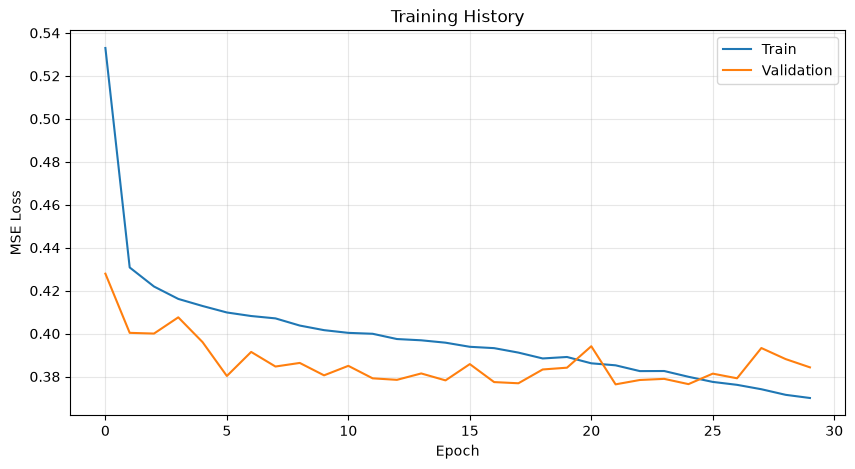

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(train_history, label="Train")

plt.plot(val_history, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [38]:
# 추론: 학습된 모델로 예측값 계산
def predict(model, loader, device):
    # 평가 모드로 전환: Dropout 비활성화
    model.eval()

    # 배치별 예측값과 실제 정답을 저장할 리스트
    preds = []
    trues = []

    # 기울기를 계산하지 않아 메모리 사용과 계산량을 줄임
    with torch.no_grad():
        for xb, yb in loader:
            # 입력과 정답을 지정한 연산 장치로 이동
            xb = xb.to(device)
            yb = yb.to(device)

            # 현재 배치의 예측값 계산
            # 일반적인 배치의 출력 크기: (64, 1)
            pred = model(xb)

            # GPU 등의 텐서를 CPU로 옮긴 뒤 NumPy 배열로 변환
            # 배치별 예측값과 정답을 각각 리스트에 추가
            preds.append(pred.cpu().numpy())
            trues.append(yb.cpu().numpy())

    # 배치별 배열을 세로로 이어 붙여 전체 결과로 반환
    # 각각의 크기: (전체 예측 데이터 수, 1)
    return np.vstack(preds), np.vstack(trues)

In [ ]:
# 테스트 데이터 전체에 대한 예측값과 실제 정답 받기
# 둘 다 표준화된 상태이며 크기는 (데이터 수, 1)
pred_scaled, true_scaled = predict(model, test_loader, DEVICE)

# 예측값을 원래 전력 단위로 복원한 뒤 1차원 배열로 변환
pred = scaler.inverse_transform(pred_scaled).ravel()

# 실제 정답도 원래 전력 단위로 복원한 뒤 1차원 배열로 변환
true = scaler.inverse_transform(true_scaled).ravel()

In [44]:
rmse = root_mean_squared_error(true, pred)
print(f'RMSE: {rmse:.4f}')

RMSE: 0.4887


In [48]:
# 전체 시퀀스의 정답 위치 중 테스트 구간에 해당하는 위치만 선택
test_indices = indices[test_mask]

# 해당 위치를 이용해 원본 시간별 데이터에서 날짜·시간 가져오기
test_dates = hourly.index[test_indices]

# 그래프에 표시할 개수: 최대 200개
# 테스트 데이터가 200개보다 적으면 있는 개수만 사용
N_VIEW = min(200, len(test_dates))

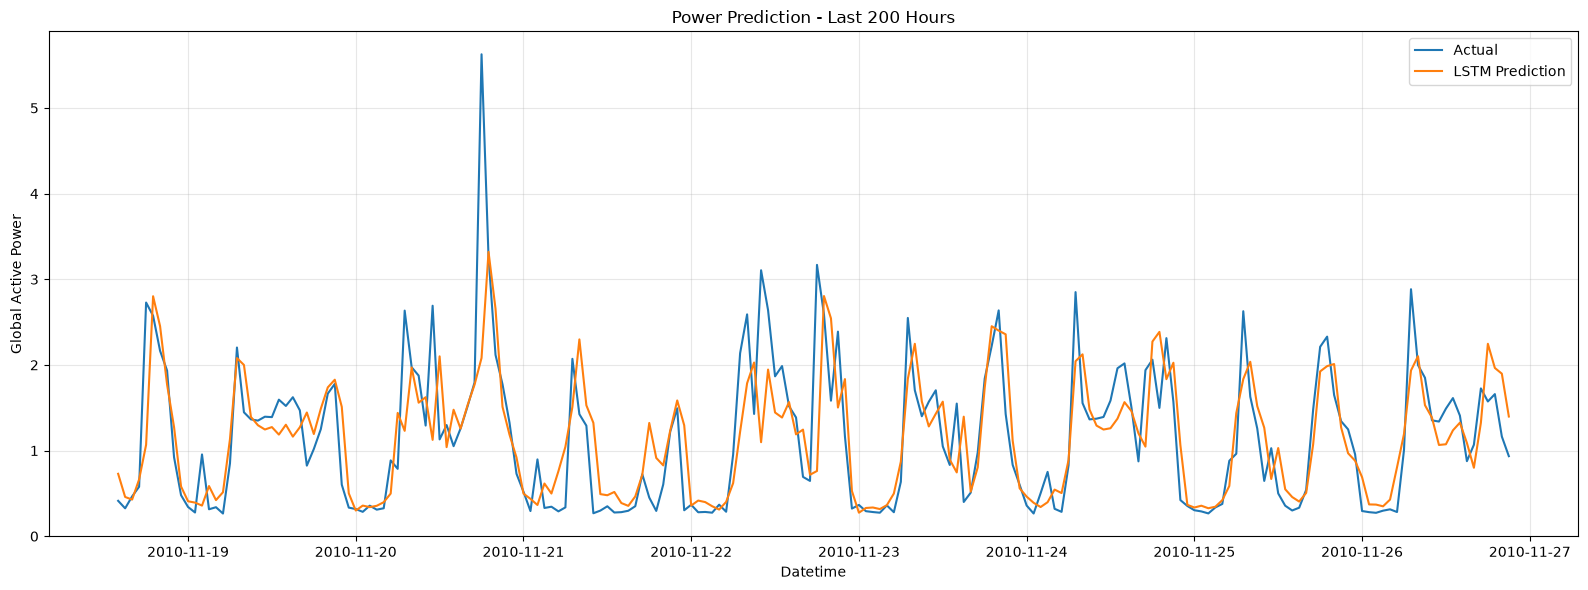

In [47]:
plt.figure(figsize=(16, 6))

plt.plot(
    test_dates[-N_VIEW:],
    true[-N_VIEW:],
    label="Actual"
)

plt.plot(
    test_dates[-N_VIEW:],
    pred[-N_VIEW:],
    label="LSTM Prediction"
)

plt.title(
    f"Power Prediction - Last {N_VIEW} Hours"
)

plt.xlabel("Datetime")
plt.ylabel("Global Active Power")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. GRU (Gated Recurrent Unit)
- GRU(Gated Recurrent Unit)는 2014년 뉴욕대학교(NYU) 조경현(Kyunghyun Cho) 교수 연구팀이 제안한 RNN의 장기 의존성 문제를 해결하기 위해 개발한 신경망 구조입니다. 
- LSTM과 유사한 성능을 가지면서도 더 간단한 구조를 갖고 있어 연산량이 적고 학습 속도가 빠릅니다. 
- GRU는 업데이트 게이트(Update Gate)와 리셋 게이트(Reset Gate)라는 두 개의 게이트만을 사용하여 정보를 조절하며, LSTM보다 파라미터 수가 적어 적은 데이터셋에서도 효과적으로 학습할 수 있습니다. 
- 업데이트 게이트는 이전 정보를 얼마나 유지할지 결정하고, 리셋 게이트는 새로운 정보를 반영하기 위해 기존 정보를 얼마나 잊을지 조정합니다. 
- 이러한 특성 덕분에 GRU는 텍스트 처리, 음성 인식, 시계열 예측 등에서 LSTM보다 더 빠르고 효율적으로 사용할 수 있지만, 장기 의존성이 중요한 경우 LSTM이 더 나은 성능을 보일 수도 있습니다.

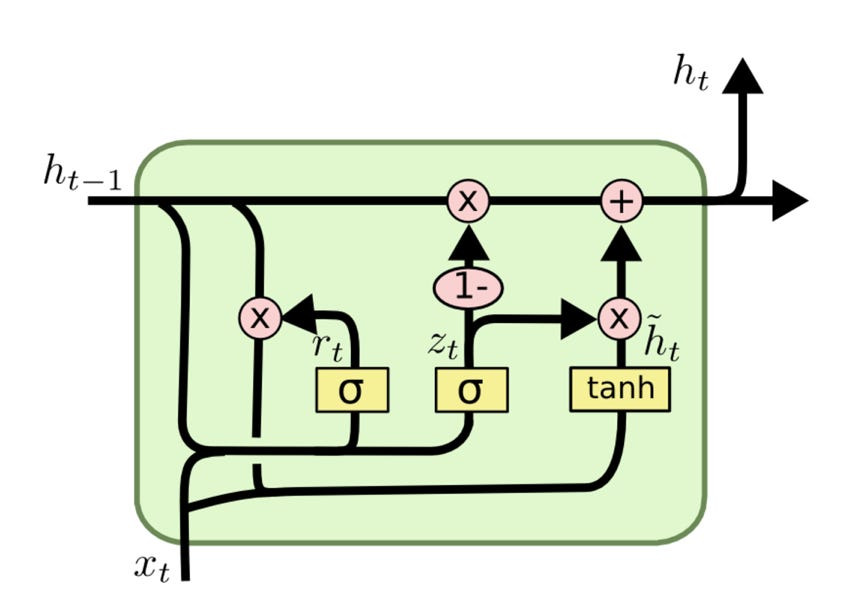

```
LSTM
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)

GRU
        self.gru = nn.GRU(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)

LSTM
        out, (h_n, c_n) = self.lstm(x)

GRU
        out, h_n = self.gru(x)

```